# NYC Airbnb Price Prediction using Linear Regression
**Student Name:** Rhydham Shukla  
**Course:** Machine Learning Program, Unlox Academy  
**Dataset:** Kaggle New York City Airbnb Open Data (AB_NYC_2019.csv)  

In this project, I build an end to end Linear Regression pipeline to predict NYC Airbnb listing prices. I follow the 7 steps outlined in our assignment brief: exploratory data analysis, data cleaning, outlier treatment via 95th percentile capping, handling categorical high cardinality, train test splitting, model training, and residual analysis.


## Step 1: Exploratory Data Analysis & Data Auditing
First, I import the required libraries and load the real Kaggle NYC Airbnb dataset. I check the shape, columns, data types, and count missing values across each feature.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

# Loading the real Kaggle NYC Airbnb dataset using a relative path
df = pd.read_csv('AB_NYC_2019.csv')
print("Dataset Shape:", df.shape)
print("\nColumns and Data Types:")
print(df.dtypes)

print("\nMissing Value Counts and Percentages:")
missing = df.isnull().sum()
missing_pct = (missing / len(df)) * 100
missing_df = pd.DataFrame({'Missing Count': missing, 'Percentage (%)': missing_pct.round(2)})
print(missing_df[missing_df['Missing Count'] > 0])


Dataset Shape: (48895, 16)

Columns and Data Types:
id                                  int64
name                               object
host_id                             int64
host_name                          object
neighbourhood_group                object
neighbourhood                      object
latitude                          float64
longitude                         float64
room_type                          object
price                               int64
minimum_nights                      int64
number_of_reviews                   int64
last_review                        object
reviews_per_month                 float64
calculated_host_listings_count      int64
availability_365                    int64
dtype: object

Missing Value Counts and Percentages:
                   Missing Count  Percentage (%)
name                          16            0.03
host_name                     21            0.04
last_review                10052           20.56
reviews_per_month          

## Step 2: Data Cleaning & Handling Missing Values
Observations from Step 1:
1. `last_review` is missing in 10,052 rows (over 20%). Since it is a date string and we already have review counts, I drop it.
2. `reviews_per_month` is missing in the exact same 10,052 rows where `number_of_reviews` is 0. If a listing has zero reviews, its reviews per month is logically 0.0, so I fill these missing values with 0.0.
3. ID columns (`id`, `name`, `host_id`, `host_name`) are just database identifiers and text names that do not help linear regression, so I drop them.


In [2]:
# Task 2.1 & 2.3: Dropping last_review and identifier columns
df_clean = df.drop(columns=['id', 'name', 'host_id', 'host_name', 'last_review'])

# Task 2.2: Filling reviews_per_month with 0.0 where reviews are zero
df_clean['reviews_per_month'] = df_clean['reviews_per_month'].fillna(0.0)

print("Remaining columns:", list(df_clean.columns))
print("Remaining missing values:", df_clean.isnull().sum().sum())


Remaining columns: ['neighbourhood_group', 'neighbourhood', 'latitude', 'longitude', 'room_type', 'price', 'minimum_nights', 'number_of_reviews', 'reviews_per_month', 'calculated_host_listings_count', 'availability_365']
Remaining missing values: 0


## Step 3: Outlier Identification & Treatment
Linear regression fits a straight line by minimizing squared errors, so extreme values pull the line heavily away from normal listings.
I check boxplots for `price` and `minimum_nights` to see the extreme values, then apply the 95th percentile capping rule specified in the brief.


Plotting raw boxplots for price and minimum_nights...


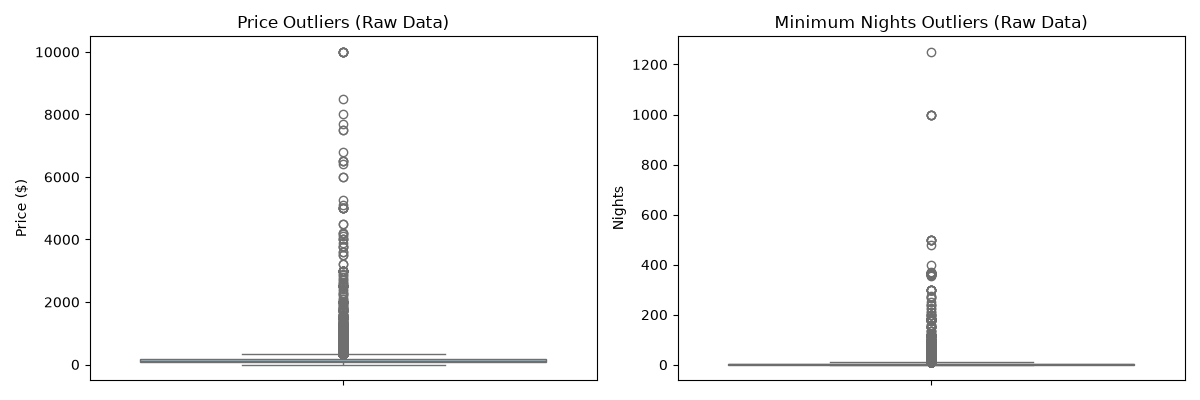

In [3]:
# Task 3.1: Visualizing raw outliers
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(y=df_clean['price'], ax=axes[0], color='skyblue')
axes[0].set_title('Price Outliers (Raw Data)')
axes[0].set_ylabel('Price ($)')

sns.boxplot(y=df_clean['minimum_nights'], ax=axes[1], color='salmon')
axes[1].set_title('Minimum Nights Outliers (Raw Data)')
axes[1].set_ylabel('Nights')
plt.tight_layout()
plt.show()


Task 3.2: Applying the 95th percentile rule.
Looking at the summary statistics, some listings are priced at $10,000 per night or require 365+ nights minimum stay. The 95th percentile for price is $355.00, and for minimum nights it is 30 nights. I filter the data to keep listings with price between $1 and $355, and minimum nights up to 30.


In [4]:
p95_price = df_clean['price'].quantile(0.95)
p95_nights = df_clean['minimum_nights'].quantile(0.95)

print(f"95th percentile threshold for Price: ${p95_price:.2f}")
print(f"95th percentile threshold for Minimum Nights: {p95_nights:.1f} nights")

# Filtering out zero prices, luxury penthouses above $355, and long-term leases over 30 nights
df_filtered = df_clean[(df_clean['price'] > 0) & (df_clean['price'] <= p95_price)]
df_filtered = df_filtered[df_filtered['minimum_nights'] <= p95_nights]

print(f"Rows before outlier filtering: {len(df_clean)}")
print(f"Rows after 95th percentile trimming: {len(df_filtered)}")
print(f"Retained {len(df_filtered) / len(df_clean) * 100:.2f}% of typical consumer listings.")


95th percentile threshold for Price: $355.00
95th percentile threshold for Minimum Nights: 30.0 nights
Rows before outlier filtering: 48895
Rows after 95th percentile trimming: 45748
Retained 93.56% of typical consumer listings.


## Step 4: Feature Selection & Categorical Encoding
Task 4.1: Addressing High Cardinality and the Curse of Dimensionality.
The `neighbourhood` column contains 221 unique specific neighborhoods, while `neighbourhood_group` contains the 5 NYC boroughs (Manhattan, Brooklyn, Queens, Bronx, Staten Island).
If I one-hot encode `neighbourhood`, it would add over 220 sparse binary columns to our dataset. This is the classic **Curse of Dimensionality**: the feature space becomes sparse, variance increases, the model risks overfitting, and features become collinear. Therefore, I drop `neighbourhood` and keep `neighbourhood_group`.

Task 4.2: One-Hot Encoding with `drop_first=True`.
I encode `neighbourhood_group` and `room_type`. Dropping the first dummy column prevents the **Dummy Variable Trap** (multicollinearity caused by dummy variables summing up to 1, which conflicts with the intercept).


In [5]:
# Task 4.1: Dropping neighbourhood to prevent the Curse of Dimensionality
df_encoded = df_filtered.drop(columns=['neighbourhood'])

# Task 4.2: One-Hot Encoding neighbourhood_group and room_type with drop_first=True
df_encoded = pd.get_dummies(df_encoded, columns=['neighbourhood_group', 'room_type'], drop_first=True)

print("Final dataset shape for modeling:", df_encoded.shape)
print("Features in model:")
for col in df_encoded.columns:
    print(" -", col)


Final dataset shape for modeling: (45748, 14)
Features in model:
 - latitude
 - longitude
 - price
 - minimum_nights
 - number_of_reviews
 - reviews_per_month
 - calculated_host_listings_count
 - availability_365
 - neighbourhood_group_Brooklyn
 - neighbourhood_group_Manhattan
 - neighbourhood_group_Queens
 - neighbourhood_group_Staten Island
 - room_type_Private room
 - room_type_Shared room


## Step 5: Feature-Target Separation & Train-Test Validation Split
I separate the target variable `price` ($y$) from the input features ($X$). Then I split the data into 80% training data and 20% testing data using `random_state=42` for exact reproducibility.


In [6]:
X = df_encoded.drop(columns=['price'])
y = df_encoded['price']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"Training feature set shape: {X_train.shape}")
print(f"Testing feature set shape:  {X_test.shape}")
print(f"Training target shape:       {y_train.shape}")
print(f"Testing target shape:        {y_test.shape}")


Training feature set shape: (36598, 13)
Testing feature set shape:  (9150, 13)
Training target shape:       (36598,)
Testing target shape:        (9150,)


## Step 6: Model Training & Evaluation
I initialize and fit a standard scikit-learn `LinearRegression` model on the training data. Then I make predictions on the hidden test set and calculate the 3 required metrics:
1. **R-Squared ($R^2$) Score**: Tells us what percentage of the variance in price our model explains.
2. **Mean Absolute Error (MAE)**: The average dollar mistake the model makes per listing.
3. **Root Mean Squared Error (RMSE)**: Penalizes larger mistakes more heavily.


In [7]:
model = LinearRegression()
model.fit(X_train, y_train)

# Generating predictions on the test set
y_pred = model.predict(X_test)

# Metric calculations
r2 = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)

print("=" * 50)
print("LINEAR REGRESSION EVALUATION METRICS (TEST SET)")
print("=" * 50)
print(f"R-Squared (R2) Score : {r2:.4f} ({r2*100:.2f}% of price variance explained)")
print(f"Mean Absolute Error  : ${mae:.2f}")
print(f"Mean Squared Error   : {mse:.2f}")
print(f"Root Mean Squared Err: ${rmse:.2f}")
print("=" * 50)


LINEAR REGRESSION EVALUATION METRICS (TEST SET)
R-Squared (R2) Score : 0.4868 (48.68% of price variance explained)
Mean Absolute Error  : $38.32
Mean Squared Error   : 2760.40
Root Mean Squared Err: $52.54


## Step 7: Residual Analysis & Final Project Questions
Task 7.1 & 7.2:
I plot a scatter plot of Actual Prices vs. Predicted Prices with a 45 degree diagonal line showing a perfect match. Next to it, I plot the residuals distribution histogram to see if the errors are normally distributed around zero.


Plotting Actual vs Predicted and Residual Distribution...


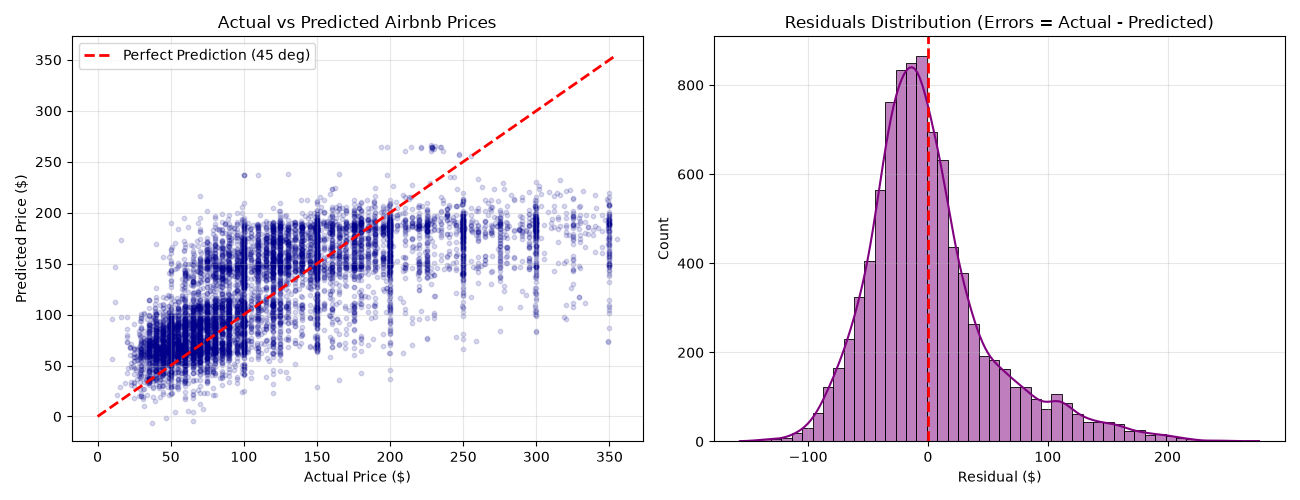

In [8]:
residuals = y_test - y_pred

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Scatter plot: Actual vs Predicted
axes[0].scatter(y_test, y_pred, alpha=0.15, color='darkblue', s=12)
axes[0].plot([0, p95_price], [0, p95_price], color='red', linestyle='--', linewidth=2, label='Perfect Prediction (45 deg line)')
axes[0].set_title('Actual vs Predicted Airbnb Prices (Test Set)')
axes[0].set_xlabel('Actual Price ($)')
axes[0].set_ylabel('Predicted Price ($)')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Residuals histogram
sns.histplot(residuals, bins=50, kde=True, ax=axes[1], color='purple')
axes[1].axvline(0, color='red', linestyle='--', linewidth=2, label='Zero Error')
axes[1].set_title('Residuals Distribution (Errors = Actual - Predicted)')
axes[1].set_xlabel('Prediction Error ($)')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


### Task 7.3: Does the model perform better on cheap listings or expensive listings, and why?

**Answer:**
Looking at the scatter plot and residual distribution, the linear regression model performs significantly better on **cheap and mid-range listings ($40 to $150)** than on expensive listings ($200 to $355).

**Why this happens:**
1. **Central Tendency Fitting:** Linear regression fits the mean relationship across the data. Because the vast majority of NYC Airbnb listings are clustered between $50 and $150, the model parameters optimize heavily to fit this central density.
2. **Missing Luxury Features:** In expensive listings, prices are driven by factors not present in our simple dataset, such as luxury amenities, skyline views, designer furniture, high end appliances, and seasonal demand surges. Since our linear model only knows basic borough and room type, it predicts a conservative price around the borough mean, leading to noticeable underprediction for luxury listings.
3. **Non-Negative Price Floor:** Cheap listings have a natural floor near $20 to $40, so errors in that region stay tightly bounded, whereas higher-priced listings exhibit much greater price variance.
